# 01. Exploración de datos — OralSolutions (PSet 3)

**Fuente:** `data/processed/obt_riesgo_abandono.csv`, generado por `src/datos.py` a partir de los puntos de predicción de Snowflake OBT y de las sesiones completadas de Gold para etiquetar la continuidad.

**Unidad:** sesión clínica atendida de un tratamiento con sesiones pendientes. 
**Target `abandono_60d`:** 1 si no consta una sesión de continuidad posterior del mismo plan dentro de 60 días; 0 si sí consta. Las 60 jornadas posteriores se usan **solo para etiquetar**, nunca como predictores.

**Momento de inferencia:** inmediatamente después de la sesión de referencia. Esta exploración es descriptiva y contiene datos de todo el CSV; las transformaciones aprendidas y la evaluación de modelos deben ajustarse exclusivamente con el conjunto de entrenamiento, respetando el corte temporal y la maduración del target. Se revisan estructura, faltantes, atípicos, desbalance, relaciones con el target y decisiones concretas para modelado.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

CANDIDATAS = [
    Path("../data/processed/obt_riesgo_abandono.csv"),
    Path("data/processed/obt_riesgo_abandono.csv"),
]
RUTA = next(p for p in CANDIDATAS if p.exists())
TARGET = "abandono_60d"
FECHAS = ["fecha_realizada", "fecha_inicio_plan"]

df = pd.read_csv(RUTA, parse_dates=FECHAS)
print("Archivo:", RUTA.resolve())
df.head()

Archivo: C:\Users\ANDRES\Desktop\proyecto_final\data\processed\obt_riesgo_abandono.csv


,sesion_key,paciente_key,plan_tratamiento_id,cita_id,odontologo_key,procedimiento_key,codigo_procedimiento,nombre_procedimiento,duracion_estimada_min,fecha_realizada,fecha_inicio_plan,numero_sesion,sesiones_planificadas,sesiones_previas,cancelaciones_previas,inasistencias_previas,dias_desde_inicio_plan,edad_en_atencion,dia_semana_atencion,mes_atencion,abandono_60d
0,1215,434,535,1194,1,10,CROWN,Porcelain crown,75,2024-01-02,2024-01-02,1,2,0,0,0,0,45,2,1,0
1,3865,1441,1720,3369,5,10,CROWN,Porcelain crown,75,2024-01-10,2024-01-10,1,3,0,0,0,0,33,3,1,1
2,6646,2453,2955,5696,5,5,FILL2,"Filling, two surfaces",50,2024-01-11,2024-01-11,1,2,0,0,0,0,26,4,1,0
3,1049,371,453,1049,2,10,CROWN,Porcelain crown,75,2024-01-16,2024-01-16,1,2,0,0,0,0,64,2,1,0
4,3127,1162,1388,2769,2,8,WHITEN,Whitening session,60,2024-01-25,2024-01-25,1,4,0,0,0,0,62,4,1,0


Cada registro del CSV corresponde a un punto de predicción asociado a una sesión atendida; las fechas se interpretan como variables temporales. La construcción de etiquetas utiliza Gold, donde también se encuentran sesiones finales no incluidas como puntos candidatos en la OBT.

## 1. Resumen del dataset

In [2]:
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
resumen = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "% faltantes": (df.isna().mean() * 100).round(2),
    "únicos": df.nunique(),
})
display(resumen)
print("Filas duplicadas (completas):", df.duplicated().sum())
print("Rango fecha_realizada:", df["fecha_realizada"].min().date(), "→", df["fecha_realizada"].max().date())

Filas: 2,377 | Columnas: 21


,dtype,faltantes,% faltantes,únicos
sesion_key,int64,0,0.0,2377
paciente_key,int64,0,0.0,1287
plan_tratamiento_id,int64,0,0.0,1576
cita_id,int64,0,0.0,2377
odontologo_key,int64,0,0.0,5
procedimiento_key,int64,0,0.0,6
codigo_procedimiento,str,0,0.0,6
nombre_procedimiento,str,0,0.0,6
duracion_estimada_min,int64,0,0.0,6
fecha_realizada,datetime64[us],0,0.0,500


Filas duplicadas (completas): 0
Rango fecha_realizada: 2024-01-02 → 2025-11-01


- El dataset etiquetado contiene **2.377 filas y 21 columnas**, sin faltantes ni filas completamente duplicadas; las fechas de referencia van del **2024-01-02 al 2025-11-01**.
- Se observan **1.287 pacientes** y **1.576 planes**. `sesion_key`, `cita_id`, `plan_tratamiento_id` y `paciente_key` se reservan para trazabilidad y validaciones, no para entrenar directamente.
- `procedimiento_key`, `codigo_procedimiento` y `nombre_procedimiento` identifican el procedimiento desde representaciones diferentes; se conservará el código como variable categórica y no las tres a la vez.

In [3]:
# Clasificación de columnas (identificadores vs numéricas vs categóricas)
IDS = ["sesion_key", "paciente_key", "plan_tratamiento_id", "cita_id",
       "odontologo_key", "procedimiento_key"]
CATEG = ["codigo_procedimiento", "nombre_procedimiento"]
NUM = [c for c in df.select_dtypes("number").columns if c not in IDS + [TARGET]]
print("Numéricas:", NUM)
display(df[NUM].describe().T.round(2))
display(df[CATEG + ["odontologo_key"]].nunique().to_frame("únicos"))
display(df["codigo_procedimiento"].value_counts().to_frame("filas"))

Numéricas: ['duracion_estimada_min', 'numero_sesion', 'sesiones_planificadas', 'sesiones_previas', 'cancelaciones_previas', 'inasistencias_previas', 'dias_desde_inicio_plan', 'edad_en_atencion', 'dia_semana_atencion', 'mes_atencion']


,count,mean,std,min,25%,50%,75%,max
duracion_estimada_min,2377.0,67.05,18.70,30.0,50.0,75.0,90.0,90.0
numero_sesion,2377.0,1.42,0.64,1.0,1.0,1.0,2.0,3.0
sesiones_planificadas,2377.0,3.00,0.82,2.0,2.0,3.0,4.0,4.0
sesiones_previas,2377.0,0.42,0.64,0.0,0.0,0.0,1.0,2.0
cancelaciones_previas,2377.0,0.10,0.33,0.0,0.0,0.0,0.0,2.0
inasistencias_previas,2377.0,0.06,0.27,0.0,0.0,0.0,0.0,3.0
dias_desde_inicio_plan,2377.0,14.51,21.93,0.0,0.0,0.0,26.0,119.0
edad_en_atencion,2377.0,44.21,21.10,6.0,26.0,45.0,63.0,80.0
dia_semana_atencion,2377.0,3.15,1.82,1.0,1.0,3.0,5.0,6.0
mes_atencion,2377.0,7.06,2.90,1.0,5.0,8.0,9.0,12.0


,únicos
codigo_procedimiento,6
nombre_procedimiento,6
odontologo_key,5


,filas
codigo_procedimiento,
ROOT,647
CROWN,570
WHITEN,519
FILL2,314
FILL1,175
EXTRACT,152


- La duración estimada está entre **30 y 90 minutos** y la edad registrada entre **6 y 80 años**; la plausibilidad no equivale a confirmar la exactitud clínica.
- Los conteos de cancelaciones e inasistencias se concentran en cero. `dias_desde_inicio_plan` tiene una cola derecha hasta **119 días**; se estudiarán con IQR y Z-score antes de decidir su tratamiento.
- Hay seis códigos de procedimiento; el menos frecuente (`EXTRACT`) contiene **152 observaciones** en el CSV completo.

## 2. Integridad y estructura (qué significa cada fila y qué grupos hay)

In [4]:
chk = {}
chk["sesion_key única"] = df["sesion_key"].is_unique
chk["sesiones_previas == numero_sesion-1 (% filas)"] = round((df["sesiones_previas"] == df["numero_sesion"] - 1).mean() * 100, 2)
dias_calc = (df["fecha_realizada"] - df["fecha_inicio_plan"]).dt.days
chk["dias_desde_inicio_plan == diferencia de fechas (%)"] = round((df["dias_desde_inicio_plan"] == dias_calc).mean() * 100, 2)
chk["dia_semana_atencion == isoweekday (%)"] = round((df["dia_semana_atencion"] == df["fecha_realizada"].dt.day_of_week + 1).mean() * 100, 2)
chk["mes_atencion == mes de fecha (%)"] = round((df["mes_atencion"] == df["fecha_realizada"].dt.month).mean() * 100, 2)
chk["numero_sesion <= sesiones_planificadas (%)"] = round((df["numero_sesion"] <= df["sesiones_planificadas"]).mean() * 100, 2)
chk["fecha_realizada >= fecha_inicio_plan (%)"] = round((dias_calc >= 0).mean() * 100, 2)
display(pd.Series(chk, name="resultado").to_frame())

g_pac = df.groupby("paciente_key").size()
g_plan = df.groupby("plan_tratamiento_id").size()
print(f"Pacientes: {g_pac.shape[0]:,} | filas por paciente: media {g_pac.mean():.2f}, máx {g_pac.max()}")
print(f"Planes: {g_plan.shape[0]:,} | filas por plan: media {g_plan.mean():.2f}, máx {g_plan.max()}")
print(f"% filas de pacientes con más de una fila: {(df['paciente_key'].map(g_pac) > 1).mean()*100:.1f}%")

,resultado
sesion_key única,True
sesiones_previas == numero_sesion-1 (% filas),100.0
dias_desde_inicio_plan == diferencia de fechas (%),100.0
dia_semana_atencion == isoweekday (%),100.0
mes_atencion == mes de fecha (%),100.0
numero_sesion <= sesiones_planificadas (%),100.0
fecha_realizada >= fecha_inicio_plan (%),100.0


Pacientes: 1,287 | filas por paciente: media 1.85, máx 7
Planes: 1,576 | filas por plan: media 1.51, máx 3
% filas de pacientes con más de una fila: 73.7%


- Las comprobaciones de consistencia de las variables derivadas y fechas alcanzan **100 %** en las 2.377 filas; `sesion_key` es única.
- El **73,7 %** de las observaciones pertenece a pacientes representados en más de una fila. Esto exige estudiar dependencia entre observaciones del mismo paciente y comparar validación temporal frente a validación por grupos, sin usar el hold-out para seleccionar modelos.

## 3. Target: distribución, desbalance y su comportamiento en el tiempo

              filas   pct
abandono_60d             
0              2056  86.5
1               321  13.5
Tasa de abandono: 0.135 | razón mayoritaria/minoritaria: 6.40:1


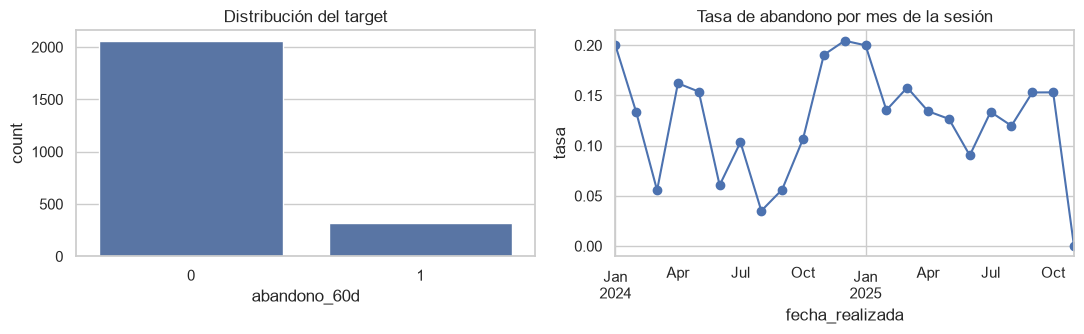

fecha_realizada,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11
tasa,0.2,0.133,0.056,0.162,0.154,0.061,0.103,0.035,0.056,0.107,0.19,0.205,0.2,0.135,0.158,0.134,0.127,0.09,0.134,0.12,0.153,0.153,0.0
filas,5.0,15.000,18.000,37.000,39.000,33.000,58.000,57.000,71.000,75.000,84.00,88.000,90.0,96.000,133.000,134.000,150.000,166.00,202.000,217.00,281.000,320.000,8.0


In [5]:
vc = df[TARGET].value_counts().sort_index()
tasa = df[TARGET].mean()
print(vc.to_frame("filas").assign(pct=(vc / len(df) * 100).round(2)))
print(f"Tasa de abandono: {tasa:.3f} | razón mayoritaria/minoritaria: {vc.max()/vc.min():.2f}:1")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(x=TARGET, data=df, ax=ax[0]); ax[0].set_title("Distribución del target")
mensual = df.groupby(df["fecha_realizada"].dt.to_period("M"))[TARGET].agg(["mean", "size"])
mensual["mean"].plot(ax=ax[1], marker="o"); ax[1].set_title("Tasa de abandono por mes de la sesión")
ax[1].set_ylabel("tasa"); plt.tight_layout(); plt.show()
display(mensual.rename(columns={"mean": "tasa", "size": "filas"}).round(3).T)

- El target corregido contiene **321 abandonos (13,50 %)** y **2.056 continuidades (86,50 %)**: desbalance aproximado **6,40:1** a favor de la clase negativa.
- Predecir siempre «continuidad» tendría una exactitud cercana al **86,5 %**, pero **recall de abandono = 0**; por ello la exactitud sola no sirve para decidir.
- La métrica técnica principal seguirá siendo **PR-AUC / Average Precision**. Debe compararse con una línea base apropiada; en este dataset su prevalencia global es 13,5 %.
- Las tasas mensuales tempranas fluctúan con muestras pequeñas, por lo que no corresponde afirmar estabilidad temporal sin considerar el número de filas de cada mes.

In [6]:
# ¿El target es constante dentro de un paciente o plan? 
for g in ["paciente_key", "plan_tratamiento_id"]:
    n = df.groupby(g)[TARGET].nunique()
    print(f"{g}: grupos con target mixto (0 y 1) = {(n > 1).sum()} de {len(n)} ({(n > 1).mean()*100:.1f}%)")

# ¿Dónde cae el abandono dentro del plan?
df["es_ultima_planificada"] = df["numero_sesion"] == df["sesiones_planificadas"]
df["es_ultima_observada"] = df["numero_sesion"] == df.groupby("plan_tratamiento_id")["numero_sesion"].transform("max")
display(df.groupby("es_ultima_planificada")[TARGET].agg(["mean", "size"]).round(3))
display(df.groupby("es_ultima_observada")[TARGET].agg(["mean", "size"]).round(3))

# Verificar cobertura de 60 días contra el cierre del historial ORIGINAL de Snowflake,
# NO contra la fecha máxima del CSV ya filtrado.
CIERRE_HISTORICO = pd.Timestamp("2025-12-31")  # verificado en Snowflake
limite_observacion = CIERRE_HISTORICO - pd.Timedelta(days=60)
df["ventana_incompleta"] = (df["fecha_realizada"] > limite_observacion)
display(df.groupby("ventana_incompleta")[TARGET].agg(["mean", "size"]).round(3))
print("Límite de referencia con target maduro:", limite_observacion.date())
assert not df["ventana_incompleta"].any(), "Hay sesiones sin 60 días completos"


paciente_key: grupos con target mixto (0 y 1) = 145 de 1287 (11.3%)
plan_tratamiento_id: grupos con target mixto (0 y 1) = 85 de 1576 (5.4%)


,mean,size
es_ultima_planificada,,
False,0.135,2377


,mean,size
es_ultima_observada,,
False,0.005,801
True,0.201,1576


,mean,size
ventana_incompleta,,
False,0.135,2377


Límite de referencia con target maduro: 2025-11-01


- Existen **145/1.287 pacientes (11,3 %)** y **85/1.576 planes (5,4 %)** con etiquetas mixtas; el riesgo se define en cada punto paciente–tratamiento–sesión, no como una etiqueta permanente del paciente.
- La OBT contiene solo sesiones de referencia **anteriores a la última sesión planificada**; el indicador `es_ultima_planificada` es falso para todas las filas, por diseño.
- La «última sesión observada en este CSV» es una propiedad calculada retrospectivamente a partir de todo el conjunto; **no debe incorporarse como feature**, pues no estaría disponible al cerrar una sesión en producción.
- La censura se controla durante la creación del CSV, tomando el cierre del historial **2025-12-31** y reteniendo referencias hasta **2025-11-01**. No debe volver a calcularse restando 60 días a la fecha máxima del CSV ya filtrado.

## 4. Valores atípicos: IQR (boxplot) y Z-score ≥ 3

,min,p50,p99,max,lim_inf_IQR,lim_sup_IQR,n_IQR,%_IQR,n_Z>=3,%_Z>=3
variable,,,,,,,,,,
duracion_estimada_min,30,75.0,90.00,90,-10.0,150.0,0,0.00,0,0.00
numero_sesion,1,1.0,3.00,3,-0.5,3.5,0,0.00,0,0.00
sesiones_planificadas,2,3.0,4.00,4,-1.0,7.0,0,0.00,0,0.00
sesiones_previas,0,0.0,2.00,2,-1.5,2.5,0,0.00,0,0.00
cancelaciones_previas,0,0.0,2.00,2,0.0,0.0,209,8.79,25,1.05
inasistencias_previas,0,0.0,1.00,3,0.0,0.0,139,5.85,139,5.85
dias_desde_inicio_plan,0,0.0,87.24,119,-39.0,65.0,100,4.21,37,1.56
edad_en_atencion,6,45.0,79.00,80,-29.5,118.5,0,0.00,0,0.00
dia_semana_atencion,1,3.0,6.00,6,-5.0,11.0,0,0.00,0,0.00


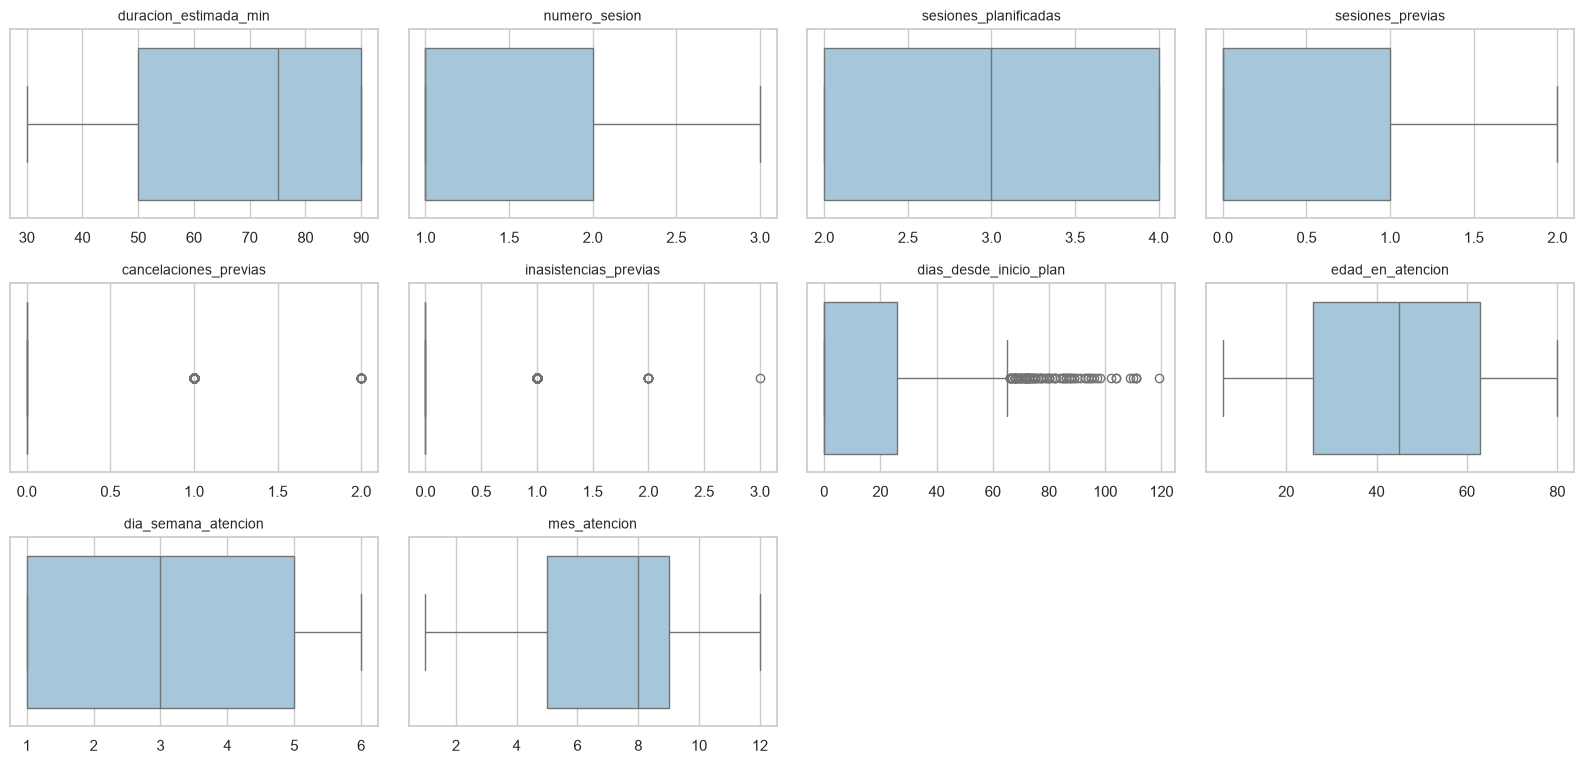

In [7]:
filas = []
for c in NUM:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = ((s < lo) | (s > hi)).sum()
    z = np.abs(stats.zscore(s)) if s.std() > 0 else np.zeros(len(s))
    filas.append({"variable": c, "min": s.min(), "p50": s.median(), "p99": s.quantile(.99), "max": s.max(),
                  "lim_inf_IQR": lo, "lim_sup_IQR": hi, "n_IQR": n_iqr, "%_IQR": round(n_iqr / len(s) * 100, 2),
                  "n_Z>=3": int((z >= 3).sum()), "%_Z>=3": round((z >= 3).mean() * 100, 2)})
atip = pd.DataFrame(filas).set_index("variable").round(2)
display(atip)

cols = NUM
n = len(cols); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.6 * nrow))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(x=df[c], ax=ax, color="#9ecae1"); ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

- Por IQR destacan `cancelaciones_previas` (**8,79 %**), `inasistencias_previas` (**5,85 %**) y `dias_desde_inicio_plan` (**4,21 %**). Con Z-score ≥3, las proporciones son **1,05 %**, **5,85 %** y **1,56 %**, respectivamente.
- En cancelaciones e inasistencias, Q1=Q3=0; por ello IQR identifica cualquier valor positivo como atípico. **No implica un error** y no justifica eliminar esos eventos de manera automática.
- Las observaciones extremas se conservan inicialmente como posibles señales conductuales; su efecto se evaluará en entrenamiento y validación.

,skew
inasistencias_previas,4.56
cancelaciones_previas,3.53
dias_desde_inicio_plan,1.63
numero_sesion,1.25
sesiones_previas,1.25
dia_semana_atencion,0.24
sesiones_planificadas,-0.00
edad_en_atencion,-0.02
duracion_estimada_min,-0.31
mes_atencion,-0.41


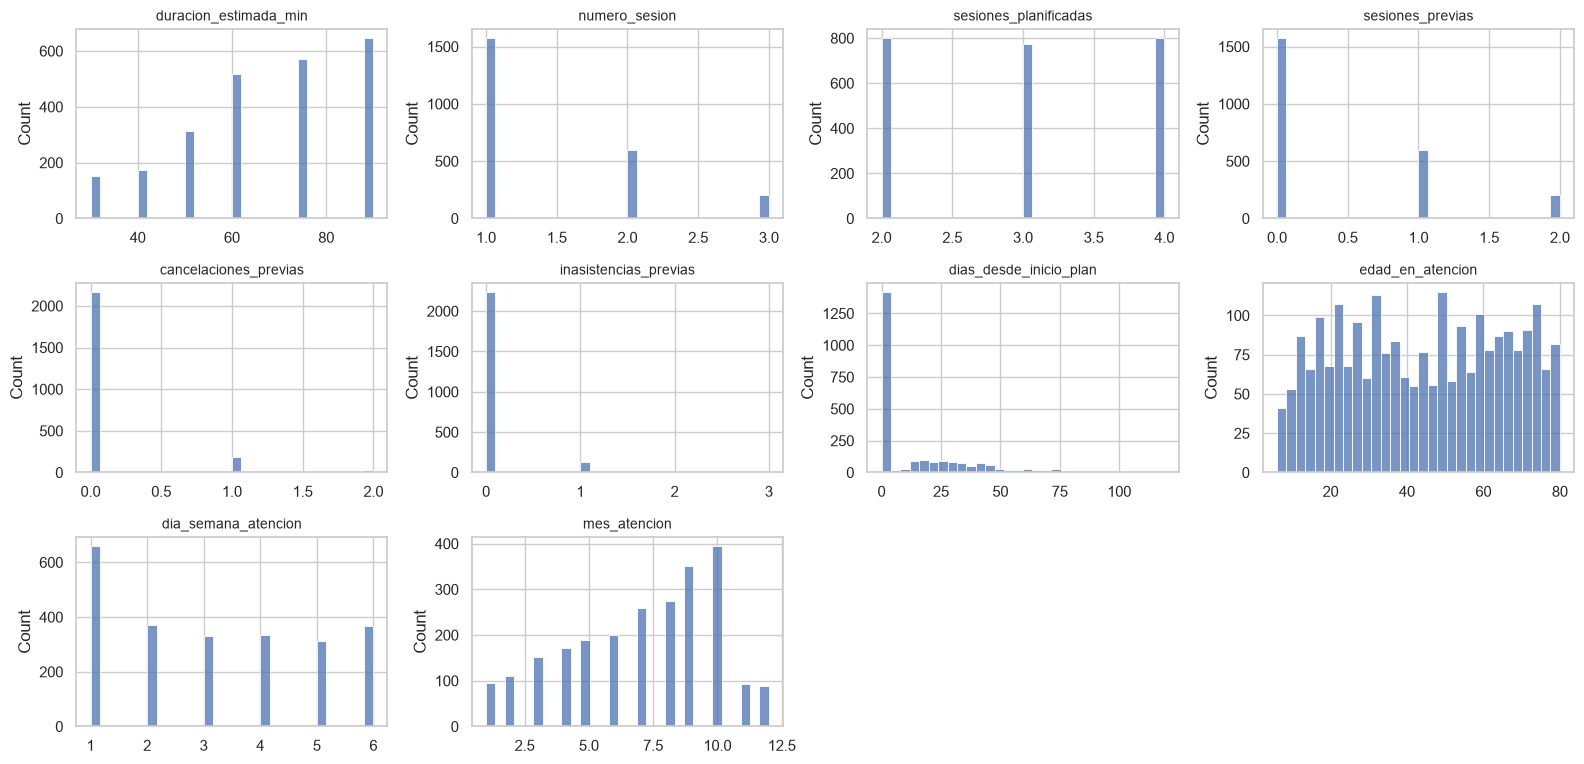

In [8]:
# Asimetría y forma de las variables de conteo / duración
display(df[NUM].skew().round(2).sort_values(ascending=False).to_frame("skew"))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.6 * nrow))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], bins=30, ax=ax); ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[n:]: ax.axis("off")
plt.tight_layout(); plt.show()

- La asimetría derecha es considerable en `inasistencias_previas` (**4,56**), `cancelaciones_previas` (**3,53**) y `dias_desde_inicio_plan` (**1,63**).
- **Decisión:** probar `RobustScaler` dentro de `ColumnTransformer` para modelos sensibles a escala, siempre ajustado únicamente en cada conjunto de entrenamiento. Los modelos de árboles no requieren necesariamente ese escalado, pero la comparación debe mantener una preparación consistente.

## 5. Relación entre el target y las características

Se utiliza **Spearman** como análisis descriptivo principal por la presencia de conteos discretos, muchos empates y distribuciones asimétricas; **Pearson** se muestra como contraste. En presencia de un target binario, estas asociaciones son descriptivas y **no demuestran causalidad, importancia predictiva fuera de muestra ni ausencia de fuga**.

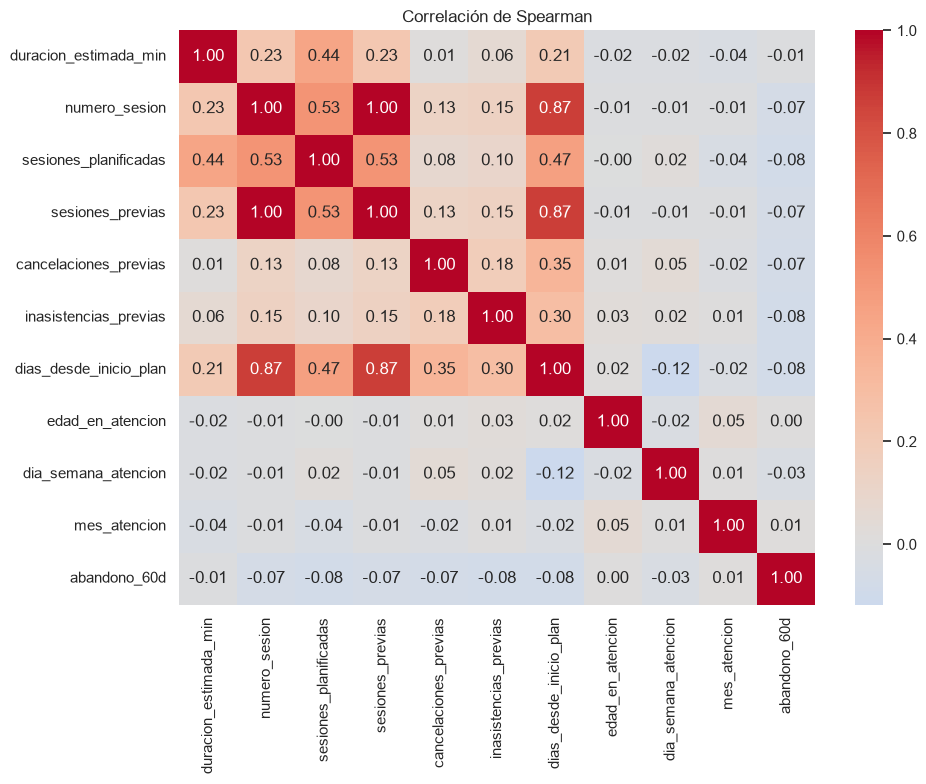

,spearman,pearson,|spearman|
dias_desde_inicio_plan,-0.081,-0.086,0.081
sesiones_planificadas,-0.080,-0.080,0.080
inasistencias_previas,-0.078,-0.076,0.078
cancelaciones_previas,-0.071,-0.069,0.071
sesiones_previas,-0.070,-0.072,0.070
numero_sesion,-0.070,-0.072,0.070
dia_semana_atencion,-0.033,-0.032,0.033
mes_atencion,0.013,0.004,0.013
duracion_estimada_min,-0.011,-0.011,0.011
edad_en_atencion,0.004,0.004,0.004


,level_0,level_1,rho
13,numero_sesion,sesiones_previas,1.000
16,numero_sesion,dias_desde_inicio_plan,0.873
36,sesiones_previas,dias_desde_inicio_plan,0.873


In [9]:
corr_s = df[NUM + [TARGET]].corr(method="spearman")
corr_p = df[NUM + [TARGET]].corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación de Spearman"); plt.tight_layout(); plt.show()

tab = pd.DataFrame({"spearman": corr_s[TARGET], "pearson": corr_p[TARGET]}).drop(TARGET)
tab["|spearman|"] = tab["spearman"].abs()
tab = tab.sort_values("|spearman|", ascending=False)
display(tab.round(3))

# Colinealidad entre predictores (|rho| >= 0.8)
pares = (corr_s.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(NUM), len(NUM))), 1).astype(bool))
        .stack().rename("rho").reset_index())
display(pares[pares["rho"].abs() >= 0.8].sort_values("rho", key=abs, ascending=False).round(3))

- La mayor asociación absoluta individual con `abandono_60d` es `dias_desde_inicio_plan` (**Spearman ρ = −0,081**), seguida de `sesiones_planificadas` (**−0,080**), `inasistencias_previas` (**−0,078**) y `cancelaciones_previas` (**−0,071**). Son **asociaciones débiles**; ya no existe la señal extrema que aparecía con el target anterior.
- `numero_sesion` y `sesiones_previas` presentan colinealidad exacta (**ρ = 1,000**) y ambas se asocian con `dias_desde_inicio_plan` (**ρ = 0,873**). Se excluirá `sesiones_previas` por redundancia, sin asumir que las demás asociaciones impliquen una fuga.
- La contribución real de cada predictor deberá evaluarse exclusivamente sobre particiones de entrenamiento y validación temporal.

## 6. Relación del target con la variable que se espera que más influya

Variable con mayor |Spearman| frente al target: dias_desde_inicio_plan


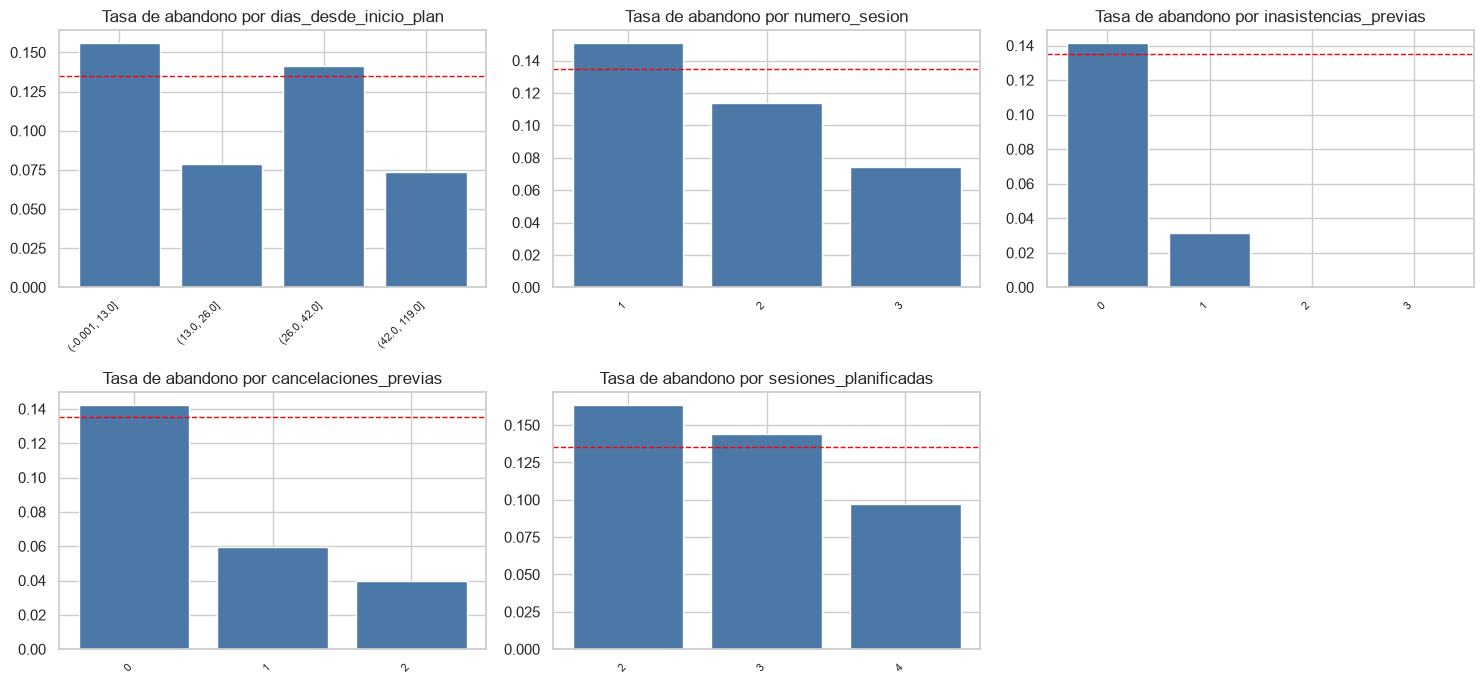

,tasa,n
dias_desde_inicio_plan,,
"(-0.001, 13.0]",0.156,1511
"(13.0, 26.0]",0.079,292
"(26.0, 42.0]",0.141,290
"(42.0, 119.0]",0.074,284


In [10]:
top = tab.index[0]
print("Variable con mayor |Spearman| frente al target:", top)

def tasa_por(df, col, q=None):
    x = df[col]
    if q and x.nunique() > 12:
        x = pd.qcut(x, q=q, duplicates="drop")
    return df.groupby(x, observed=True)[TARGET].agg(tasa="mean", n="size")

vars_clave = list(dict.fromkeys([top, "numero_sesion", "inasistencias_previas", "cancelaciones_previas",
                                "dias_desde_inicio_plan", "sesiones_planificadas"]))
vars_clave = [v for v in vars_clave if v in df.columns]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, v in zip(axes.ravel(), vars_clave):
    t = tasa_por(df, v, q=8)
    ax.bar(range(len(t)), t["tasa"], color="#4c78a8")
    ax.set_xticks(range(len(t))); ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha="right", fontsize=8)
    ax.axhline(df[TARGET].mean(), color="red", ls="--", lw=1); ax.set_title(f"Tasa de abandono por {v}")
for ax in axes.ravel()[len(vars_clave):]: ax.axis("off")
plt.tight_layout(); plt.show()
display(tasa_por(df, top, q=8).round(3))

- La variable con mayor correlación absoluta es `dias_desde_inicio_plan`, pero su **ρ = −0,081** representa una relación monótona débil.
- Por intervalos de días desde el comienzo, las tasas observadas son **15,6 %** (0–13 días; n=1.511), **7,9 %** (14–26; n=292), **14,1 %** (27–42; n=290) y **7,4 %** (>42; n=284). La secuencia no es monótona y no permite afirmar que más demora implique más abandono.
- El avance del plan y el procedimiento deben estudiarse, pero sus relaciones ya no son deterministas con el target corregido.

In [11]:
# Progreso en el plan y tasa por procedimiento / día / mes
df["progreso_plan"] = df["numero_sesion"] / df["sesiones_planificadas"]
display(tasa_por(df, "progreso_plan", q=5).round(3))
for c in ["codigo_procedimiento", "dia_semana_atencion", "mes_atencion", "odontologo_key"]:
    print(f"\n— {c}")
    display(tasa_por(df, c).round(3).T)

# Prueba estadística simple para la variable top (Mann-Whitney entre clases)
a = df.loc[df[TARGET] == 1, top]; b = df.loc[df[TARGET] == 0, top]
u = stats.mannwhitneyu(a, b)
print(f"Mann-Whitney {top}: p = {u.pvalue:.3g} | mediana abandona = {a.median()} vs no abandona = {b.median()}")

,tasa,n
progreso_plan,,
0.250000,0.104,335
0.333333,0.163,441
0.500000,0.149,1064
0.666667,0.119,335
0.750000,0.074,202



— codigo_procedimiento


codigo_procedimiento,CROWN,EXTRACT,FILL1,FILL2,ROOT,WHITEN
tasa,0.132,0.132,0.16,0.143,0.133,0.129
n,570.000,152.000,175.00,314.000,647.000,519.000



— dia_semana_atencion


dia_semana_atencion,1,2,3,4,5,6
tasa,0.153,0.14,0.142,0.101,0.122,0.134
n,660.000,372.00,331.000,336.000,311.000,367.000



— mes_atencion


mes_atencion,1,2,3,4,5,6,7,8,9,10,11,12
tasa,0.2,0.135,0.146,0.14,0.132,0.085,0.127,0.102,0.134,0.144,0.174,0.205
n,95.0,111.000,151.000,171.00,189.000,199.000,260.000,274.000,352.000,395.000,92.000,88.000



— odontologo_key


odontologo_key,1,2,3,4,5
tasa,0.103,0.148,0.152,0.126,0.146
n,446.000,466.000,435.000,501.000,529.000


Mann-Whitney dias_desde_inicio_plan: p = 7.61e-05 | mediana abandona = 0.0 vs no abandona = 0.0


- La tasa de abandono por progreso del plan varía entre **7,4 % y 16,3 %** en los valores observados; no existe una tasa del 100 % en las penúltimas sesiones.
- Por procedimiento, las tasas van aproximadamente de **12,9 % (`WHITEN`) a 16,0 % (`FILL1`)**; los procedimientos `EXTRACT` y `FILL1` **ya no presentan abandono del 100 %**.
- Entre los cinco odontólogos las tasas oscilan de **10,3 % a 15,2 %**. Hay variaciones por día y mes, pero no pueden considerarse efectos estables sin evaluar tamaño muestral y validación fuera de muestra.

## 7. Candidatos a hallazgos (revisión de fuga, grupos y tiempo)

In [12]:
hall = {}
# a) ¿El target depende del avance del plan de forma determinista? (posible fuga / regla trivial)
hall["tasa en última sesión planificada"] = df.loc[df["es_ultima_planificada"], TARGET].mean()
hall["tasa en sesiones no finales"] = df.loc[~df["es_ultima_planificada"], TARGET].mean()
# b) Censura a la derecha
hall["tasa con ventana completa"] = df.loc[~df["ventana_incompleta"], TARGET].mean()
hall["filas con ventana incompleta"] = int(df["ventana_incompleta"].sum())
hall["% filas con ventana incompleta"] = df["ventana_incompleta"].mean() * 100
# c) Dependencia entre filas del mismo paciente (necesidad de GroupKFold)
hall["% filas en pacientes con >1 fila"] = (df["paciente_key"].map(g_pac) > 1).mean() * 100
hall["filas por paciente (media)"] = g_pac.mean()
# d) Desbalance
hall["tasa de abandono"] = tasa
# e) Atípicos
hall["variable con más atípicos IQR"] = atip["%_IQR"].idxmax() + f" ({atip['%_IQR'].max()}%)"
display(pd.Series(hall, name="valor").to_frame())

# Cobertura temporal del target y volumen por periodo (para decidir el esquema de división)
display(df.groupby(df["fecha_realizada"].dt.to_period("Q"))[TARGET].agg(tasa="mean", filas="size").round(3).T)

,valor
tasa en última sesión planificada,NaN
tasa en sesiones no finales,0.135044
tasa con ventana completa,0.135044
filas con ventana incompleta,0
% filas con ventana incompleta,0.0
% filas en pacientes con >1 fila,73.706353
filas por paciente (media),1.846931
tasa de abandono,0.135044
variable con más atípicos IQR,cancelaciones_previas (8.79%)


fecha_realizada,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4
tasa,0.105,0.128,0.065,0.17,0.163,0.116,0.137,0.149
filas,38.000,109.000,186.000,247.00,319.000,450.000,700.000,328.000


- La tasa trimestral observada fluctúa: por ejemplo **6,5 % en 2024-T3** y **17,0 % en 2024-T4**, frente a **13,7 % en 2025-T3**. No se sostiene la afirmación anterior de estabilidad entre 60 % y 66 %.
- El **73,7 %** de las filas corresponde a pacientes repetidos. La validación principal seguirá siendo temporal por el objetivo de predecir sesiones futuras; se añadirá una comparación por grupos de pacientes para estudiar dependencia entre observaciones.

### 7.1 Verificación del hallazgo 1: sesiones que quedan en el plan

In [13]:

df["sesiones_restantes"] = df["sesiones_planificadas"] - df["numero_sesion"]
display(df.groupby("sesiones_restantes")[TARGET].agg(tasa="mean", filas="size").round(3))
display(df.groupby(["sesiones_planificadas", "numero_sesion"])[TARGET].agg(tasa="mean", filas="size").round(3))

# Regla simple: abandona si falta exactamente 1 sesión
pred = (df["sesiones_restantes"] == 1).astype(int)
acc = (pred == df[TARGET]).mean()
rec = (pred[df[TARGET] == 1] == 1).mean()
prec = df.loc[pred == 1, TARGET].mean()
print(f"Regla 'falta 1 sesión' -> accuracy {acc:.3f} | recall {rec:.3f} | precisión {prec:.3f}")


,tasa,filas
sesiones_restantes,,
1,0.139,1337
2,0.142,705
3,0.104,335


tasa  filas
sesiones_planificadas numero_sesion              
2                     1              0.164    800
3                     1              0.163    441
                      2              0.119    335
4                     1              0.104    335
                      2              0.106    264
                      3              0.074    202

Regla 'falta 1 sesión' -> accuracy 0.459 | recall 0.579 | precisión 0.139


- Cuando falta **1 sesión**, la tasa de abandono es **13,9 %** (n=1.337); con **2 restantes**, **14,2 %** (n=705); con **3 restantes**, **10,4 %** (n=335). Ya **no existe** la relación determinista previa.
- La regla «predecir abandono si falta exactamente una sesión» obtiene **45,9 % de exactitud**, **13,9 % de precisión** y **57,9 % de recall** sobre el conjunto explorado. Es una regla débil, no una línea base exigente.
- La línea base ingenua adecuada es predecir la clase mayoritaria («continuidad»), complementada por una línea base operativa que use **solo información disponible al cerrar la sesión**. Cualquier regla que requiera esperar 14 días después de la próxima cita no es válida para este momento de inferencia.

,tasa,n
sesiones_restantes,,
1,0.139,1337
2,0.142,705
3,0.104,335


Regla 'falta 1 sesión' -> Exactitud: 45.9% | Precisión: 13.9% | Recall: 57.9%
inasistencias_previas >= 2 -> tasa=0.0% (n=11)
dias_desde_inicio_plan > 42 -> tasa=7.4% (n=284)


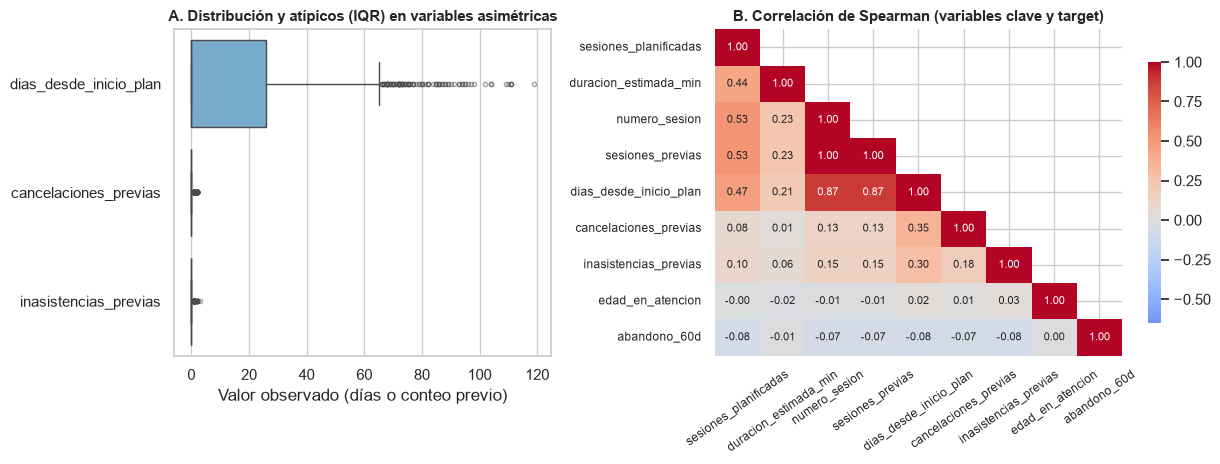

In [14]:
# Verificación numérica explícita para los Hallazgos 1 y 2 + Figura 1 del informe técnico
df["sesiones_restantes"] = df["sesiones_planificadas"] - df["numero_sesion"]
res_restantes = df.groupby("sesiones_restantes")[TARGET].agg(tasa="mean", n="size").round(3)
display(res_restantes)

pred_regla_1ses = (df["sesiones_restantes"] == 1).astype(int)
acc_1ses = (pred_regla_1ses == df[TARGET]).mean()
prec_1ses = df.loc[pred_regla_1ses == 1, TARGET].mean()
rec_1ses = df.loc[df[TARGET] == 1, "sesiones_restantes"].eq(1).mean()
print(f"Regla 'falta 1 sesión' -> Exactitud: {acc_1ses:.1%} | Precisión: {prec_1ses:.1%} | Recall: {rec_1ses:.1%}")

sub_inas = df.loc[df["inasistencias_previas"] >= 2, TARGET]
sub_dias = df.loc[df["dias_desde_inicio_plan"] > 42, TARGET]
print(f"inasistencias_previas >= 2 -> tasa={sub_inas.mean():.1%} (n={len(sub_inas)})")
print(f"dias_desde_inicio_plan > 42 -> tasa={sub_dias.mean():.1%} (n={len(sub_dias)})")

# Figura 1 compuesta (2 paneles equilibrados) para el documento técnico
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.35]})

# Panel izquierdo: Boxplots horizontales (IQR) de las 3 variables con asimetría derecha
vars_asim = ["dias_desde_inicio_plan", "cancelaciones_previas", "inasistencias_previas"]
df_melt = df[vars_asim].melt(var_name="Variable", value_name="Valor")
sns.boxplot(
    data=df_melt,
    x="Valor",
    y="Variable",
    ax=axes[0],
    palette=["#6baed6", "#fd8d3c", "#e6550d"],
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.5},
    hue="Variable",
    legend=False
)
axes[0].set_title("A. Distribución y atípicos (IQR) en variables asimétricas", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("Valor observado (días o conteo previo)")
axes[0].set_ylabel("")

# Panel derecho: Heatmap de Spearman enfocado en variables clave + target
cols_corr = [
    "sesiones_planificadas",
    "duracion_estimada_min",
    "numero_sesion",
    "sesiones_previas",
    "dias_desde_inicio_plan",
    "cancelaciones_previas",
    "inasistencias_previas",
    "edad_en_atencion",
    TARGET,
]
corr_sp = df[cols_corr].corr(method="spearman")
mask = np.triu(np.ones_like(corr_sp, dtype=bool), k=1)
sns.heatmap(
    corr_sp,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-0.65,
    vmax=1.0,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 8},
    ax=axes[1],
)
axes[1].set_title("B. Correlación de Spearman (variables clave y target)", fontsize=10.5, fontweight="bold")
axes[1].tick_params(axis="x", rotation=35, labelsize=8.5)
axes[1].tick_params(axis="y", labelsize=8.5)

plt.tight_layout()
plt.show()

## 8. Hallazgos que afectan el modelado

| Hallazgo | Evidencia de este EDA | Consecuencia experimental |
|---|---|---|
| **1. El abandono no depende de forma determinista del avance del plan** | La tasa positiva es **13,9 %** con una sesión restante (n=1.337), **14,2 %** con dos (n=705) y **10,4 %** con tres (n=335). La regla «falta una sesión» produce **precisión 13,9 %** y **exactitud 45,9 %**. `numero_sesion` y `sesiones_previas` tienen ρ=1,000. | No tomar la regla «falta una sesión» como baseline fuerte. Eliminar `sesiones_previas` por redundancia y estudiar `progreso_plan` como feature derivada **sin presuponer que aporte**. Evaluar su utilidad por CV temporal. |
| **2. Historiales con colas derechas y asociaciones individuales débiles** | IQR señala **8,79 %** de cancelaciones, **5,85 %** de inasistencias y **4,21 %** de días desde inicio. Sus asimetrías son **3,53**, **4,56** y **1,63**. `dias_desde_inicio_plan` tiene la mayor correlación absoluta con el target, pero solo **ρ=−0,081**; con >42 días el abandono es **7,4 %** (n=284) y con ≥2 inasistencias **0 %** (n=11). | Conservar eventos extremos, usar imputación/escalado dentro de CV, y **poner a prueba** `ritmo_dias_por_sesion` y `friccion_previa`; no afirmar que mejorarán el modelo sin contrastarlo en validación. |
| **3. Clase positiva minoritaria y repetición por paciente** | **321/2.377** observaciones positivas (**13,50 %**), razón de clases **6,40:1**. El **73,7 %** de las filas pertenece a pacientes con varias observaciones. Los procedimientos muestran tasas entre **12,9 % y 16,0 %**, sin separaciones extremas. | Usar **Average Precision / PR-AUC**, reportar precision-recall y comparar con baselines. Priorizar partición temporal con maduración de 60 días, comparar con validación por paciente y verificar de forma empírica el aporte de categorías y de `complejidad_proc`. |
